# Pruning

**Idea:** set the smallest weights of a trained network to zero and see how much accuracy we lose.


In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

# Folders for the dataset and for saved results
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")  # data/ and outputs/ will now be created here
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [2]:
# Fashion-MNIST: 28x28 grayscale pictures of clothes, 10 classes
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Shuffle once, then use 12,000 images for training and 3,000 for validation
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:12000].tolist())
val_data = Subset(full_train, idx[12000:15000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 12000 3000 10000


In [3]:
# A simple neural network: 784 pixels -> 256 -> 128 -> 10 classes
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.layers(x)

In [4]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Step 1: Train one baseline model

In [5]:
baseline = MLP()
history, secs = train(baseline, train_loader)

epoch 1/3  train_loss=0.6612  val_loss=0.4516  val_acc=0.8360
epoch 2/3  train_loss=0.4411  val_loss=0.4100  val_acc=0.8507
epoch 3/3  train_loss=0.3852  val_loss=0.3902  val_acc=0.8580


## Step 2: Prune copies of it (30% and 60% of weights)

"Global" pruning removes the smallest weights across all layers together.

In [6]:
from torch.nn.utils import prune

def prune_model(model, amount):
    layers = [(m, "weight") for m in model.modules() if isinstance(m, nn.Linear)]
    prune.global_unstructured(layers, pruning_method=prune.L1Unstructured, amount=amount)
    for m, name in layers:
        prune.remove(m, name)  # make the zeros permanent

def sparsity(model):
    """Fraction of Linear-layer weights that are exactly zero."""
    weights = [m.weight for m in model.modules() if isinstance(m, nn.Linear)]
    zeros = sum((w == 0).sum().item() for w in weights)
    total = sum(w.numel() for w in weights)
    return zeros / total

rows = []
for name, amount in [("baseline", 0.0), ("pruned_30", 0.3), ("pruned_60", 0.6)]:
    model = copy.deepcopy(baseline)   # copy so each test starts from the same trained model
    if amount > 0:
        prune_model(model, amount)
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({"model": name, "requested_pruning": amount,
                 "actual_sparsity": sparsity(model), "test_accuracy": test_acc})

results = pd.DataFrame(rows)
results.to_csv("outputs/pruning_results.csv", index=False)
print(results)

       model  requested_pruning  actual_sparsity  test_accuracy
0   baseline                0.0         0.000000         0.8406
1  pruned_30                0.3         0.300002         0.8412
2  pruned_60                0.6         0.599999         0.8415


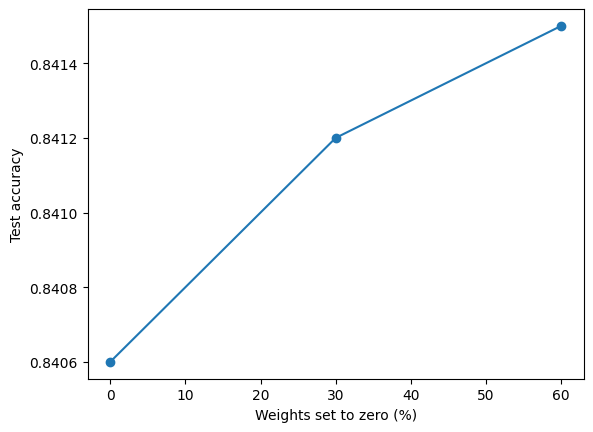

In [7]:
plt.plot(results["actual_sparsity"] * 100, results["test_accuracy"], marker="o")
plt.xlabel("Weights set to zero (%)")
plt.ylabel("Test accuracy")
plt.savefig('outputs/pruning_accuracy_test.png')
plt.show()